In [36]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb

import shap
shap.initjs()

In [40]:
print(os.getcwd())

c:\Users\W10\OneDrive\Escritorio


In [42]:
os.chdir("shapley-values")

In [43]:
# import dataset
data = pd.read_csv("data/abalone/abalone.data",
                   names = ["sex", "length", "diameter", "height",
                   "whole weight", "shucked weight", "viscera weight",
                   "shell weight", "rings"])

print(len(data))
data.head()

4177


,sex,length,diameter,height,whole weight,shucked weight,viscera weight,shell weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


Text(0.5, 0, 'whole weight')

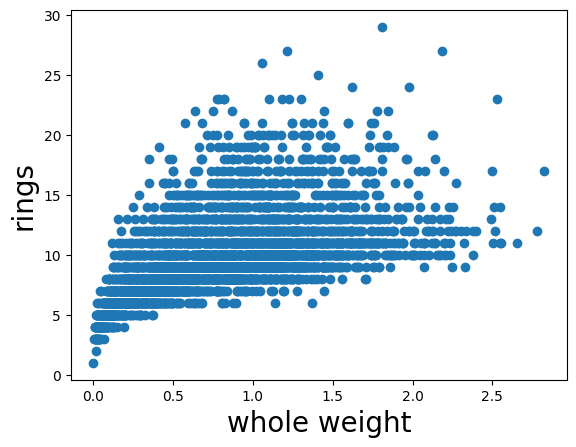

In [44]:
#Plot 1: whole weight vs rings
plt.scatter(data['whole weight'], data['rings'])
plt.ylabel('rings', size = 20)
plt.xlabel('whole weight', size=20)

Text(0.5, 0, 'Sex')

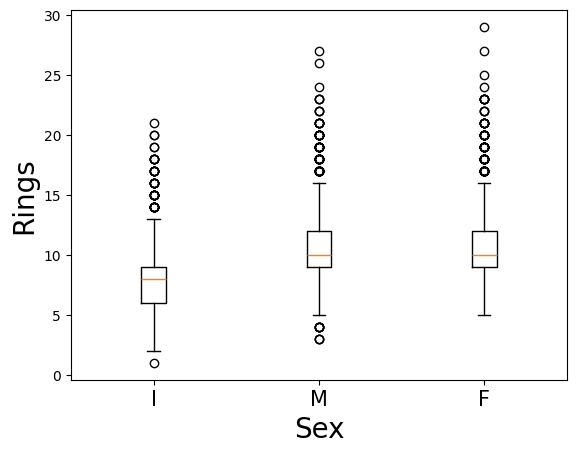

In [45]:
plt.boxplot(data[data.sex=='I']['rings'], positions=[1])
plt.boxplot(data[data.sex=='M']['rings'], positions=[2])
plt.boxplot(data[data.sex=='F']['rings'], positions=[3])

plt.xticks(ticks=[1,2,3], labels=['I', 'M', 'F'], size=15)
plt.ylabel('Rings', size=20)
plt.xlabel('Sex', size=20)

In [46]:
cont = ['length', 'diameter', 'height', 'whole weight', 'shucked weight', 'viscera weight', 'shell weight', 'rings']
data[cont]

,length,diameter,height,whole weight,shucked weight,viscera weight,shell weight,rings
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
...,...,...,...,...,...,...,...,...
4172,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


In [47]:
#Plot 3: Correlationm heatmap for continuous variables
cont = ['length', 'diameter', 'height', 'whole weight', 'shucked weight', 'viscera weight', 'shell weight', 'rings']
corr_matrix = pd.DataFrame(data[cont], columns=cont).corr()

In [48]:
print(corr_matrix)

                  length  diameter    height  whole weight  shucked weight  \
length          1.000000  0.986812  0.827554      0.925261        0.897914   
diameter        0.986812  1.000000  0.833684      0.925452        0.893162   
height          0.827554  0.833684  1.000000      0.819221        0.774972   
whole weight    0.925261  0.925452  0.819221      1.000000        0.969405   
shucked weight  0.897914  0.893162  0.774972      0.969405        1.000000   
viscera weight  0.903018  0.899724  0.798319      0.966375        0.931961   
shell weight    0.897706  0.905330  0.817338      0.955355        0.882617   
rings           0.556720  0.574660  0.557467      0.540390        0.420884   

                viscera weight  shell weight     rings  
length                0.903018      0.897706  0.556720  
diameter              0.899724      0.905330  0.574660  
height                0.798319      0.817338  0.557467  
whole weight          0.966375      0.955355  0.540390  
shucked weig

<Axes: >

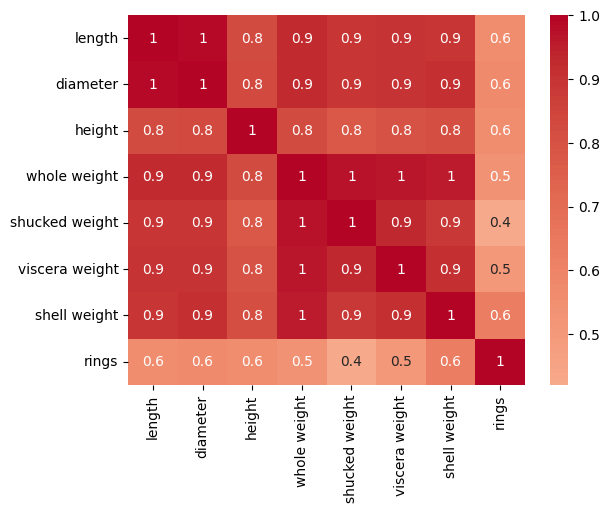

In [49]:
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center = 0,
    annot = True,
    fmt='.1g'
)

## Feature Engineering

In [50]:
Y = data['rings']
X = data[['sex', 'length', 'height', 'shucked weight', 'viscera weight', 'shell weight']]


In [51]:
# Create dummy variables 
X['sex.M'] = [1 if s == 'M' else 0 for s in X['sex']]
X['sex.I'] = [1 if s == 'I' else 0 for s in X['sex']]
X['sex.F'] = [1 if s == 'F' else 0 for s in X['sex']]

X.head()

C:\Users\W10\AppData\Local\Temp\ipykernel_17768\4233405461.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['sex.M'] = [1 if s == 'M' else 0 for s in X['sex']]
C:\Users\W10\AppData\Local\Temp\ipykernel_17768\4233405461.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['sex.I'] = [1 if s == 'I' else 0 for s in X['sex']]


,sex,length,height,shucked weight,viscera weight,shell weight,sex.M,sex.I,sex.F
0,M,0.455,0.095,0.2245,0.1010,0.150,1,0,0
1,M,0.350,0.090,0.0995,0.0485,0.070,1,0,0
2,F,0.530,0.135,0.2565,0.1415,0.210,0,0,1
3,M,0.440,0.125,0.2155,0.1140,0.155,1,0,0
4,I,0.330,0.080,0.0895,0.0395,0.055,0,1,0


In [52]:
X['sex.M']=X['sex'].eq("M").astype(int)
X['sex.I']=X['sex'].eq("I").astype(int)
X['sex.F']=X['sex'].eq("F").astype(int)

In [53]:
X.drop(columns='sex')

,length,height,shucked weight,viscera weight,shell weight,sex.M,sex.I,sex.F
0,0.455,0.095,0.2245,0.1010,0.1500,1,0,0
1,0.350,0.090,0.0995,0.0485,0.0700,1,0,0
2,0.530,0.135,0.2565,0.1415,0.2100,0,0,1
3,0.440,0.125,0.2155,0.1140,0.1550,1,0,0
4,0.330,0.080,0.0895,0.0395,0.0550,0,1,0
...,...,...,...,...,...,...,...,...
4172,0.565,0.165,0.3700,0.2390,0.2490,0,0,1
4173,0.590,0.135,0.4390,0.2145,0.2605,1,0,0
4174,0.600,0.205,0.5255,0.2875,0.3080,1,0,0
4175,0.625,0.150,0.5310,0.2610,0.2960,0,0,1


In [54]:
print(type('sex.M'))

<class 'str'>


In [ ]:
# # W3 could do it automatically

# df = pd.get_dummies(
#     data,
#     columns=["sex"],
#     dtype = str
# )

# print(df.head)

<bound method NDFrame.head of       length  diameter  height  whole weight  shucked weight  viscera weight  \
0      0.455     0.365   0.095        0.5140          0.2245          0.1010   
1      0.350     0.265   0.090        0.2255          0.0995          0.0485   
2      0.530     0.420   0.135        0.6770          0.2565          0.1415   
3      0.440     0.365   0.125        0.5160          0.2155          0.1140   
4      0.330     0.255   0.080        0.2050          0.0895          0.0395   
...      ...       ...     ...           ...             ...             ...   
4172   0.565     0.450   0.165        0.8870          0.3700          0.2390   
4173   0.590     0.440   0.135        0.9660          0.4390          0.2145   
4174   0.600     0.475   0.205        1.1760          0.5255          0.2875   
4175   0.625     0.485   0.150        1.0945          0.5310          0.2610   
4176   0.710     0.555   0.195        1.9485          0.9455          0.3765   

      she

In [55]:
dummy_cols =['sex.M', 'sex.I', 'sex.F']
X[dummy_cols]=X[dummy_cols].astype(int)

## Modelling

In [56]:
X = X.drop(columns='sex', errors='ignore')

In [57]:
# Train model
model = xgb.XGBRegressor(objective="reg:squarederror")
model.fit(X, Y)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [58]:
y_pred = model.predict(X)
print(len(y_pred))

4177


Text(0.5, 0, 'Actual')

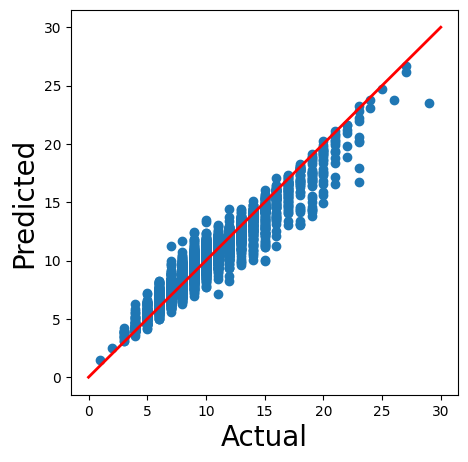

In [59]:
plt.figure(figsize=(5,5))
plt.scatter(Y, y_pred)
plt.plot([0,30], [0,30], color = 'r', linestyle = '-', linewidth=2)
plt.ylabel('Predicted', size=20)
plt.xlabel('Actual', size=20)

## Standard SHAP values

In [60]:
import sys
import shap
import xgboost as xgb

print("Python:", sys.version)
print("SHAP:", shap.__version__)
print("XGBoost:", xgb.__version__)

Python: 3.10.8 (tags/v3.10.8:aaaf517, Oct 11 2022, 16:50:30) [MSC v.1933 64 bit (AMD64)]
SHAP: 0.49.1
XGBoost: 2.1.4


In [58]:
%pip install "xgboost==2.1.4"

   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
    --------------------------------------- 2.6/124.9 MB 18.9 MB/s eta 0:00:07
   --- ------------------------------------ 11.3/124.9 MB 30.6 MB/s eta 0:00:04
   ------ --------------------------------- 19.7/124.9 MB 34.5 MB/s eta 0:00:04
   --------- ------------------------------ 28.8/124.9 MB 35.9 MB/s eta 0:00:03
   ------------ --------------------------- 37.5/124.9 MB 37.2 MB/s eta 0:00:03
   --------------- ------------------------ 48.0/124.9 MB 39.7 MB/s eta 0:00:02
   ------------------ --------------------- 58.5/124.9 MB 40.9 MB/s eta 0:00:02
   --------------------- ------------------ 67.9/124.9 MB 41.2 MB/s eta 0:00:02
   ------------------------- -------------- 78.6/124.9 MB 42.1 MB/s eta 0:00:02
   ---------------------------- ----------- 89.1/124.9 MB 42.8 MB/s eta 0:00:01
   ------------------------------- -------- 99.6/124.9 MB 43.3 MB/s eta 0:00:01
   --------------------------------- ----- 107.5/1

  You can safely remove it manually.


In [61]:
# Get shap values
explainer = shap.Explainer(model)
shap_values = explainer(X)

In [62]:
np.shape(shap_values.values)
# Looking at the print result, we have 8 shap values for each of the observations

(4177, 8)

In [63]:
shap_values[0]

.values =
array([ 0.36750534,  1.0577261 ,  0.94834965, -0.05403227, -0.43476838,
        0.33248705,  0.32200822, -0.05015277], dtype=float32)

.base_values =
np.float32(9.93266)

.data =
array([0.455 , 0.095 , 0.2245, 0.101 , 0.15  , 1.    , 0.    , 0.    ])

In [73]:
print(shap_values.feature_names)

['length', 'height', 'shucked weight', 'viscera weight', 'shell weight', 'sex.M', 'sex.I', 'sex.F']


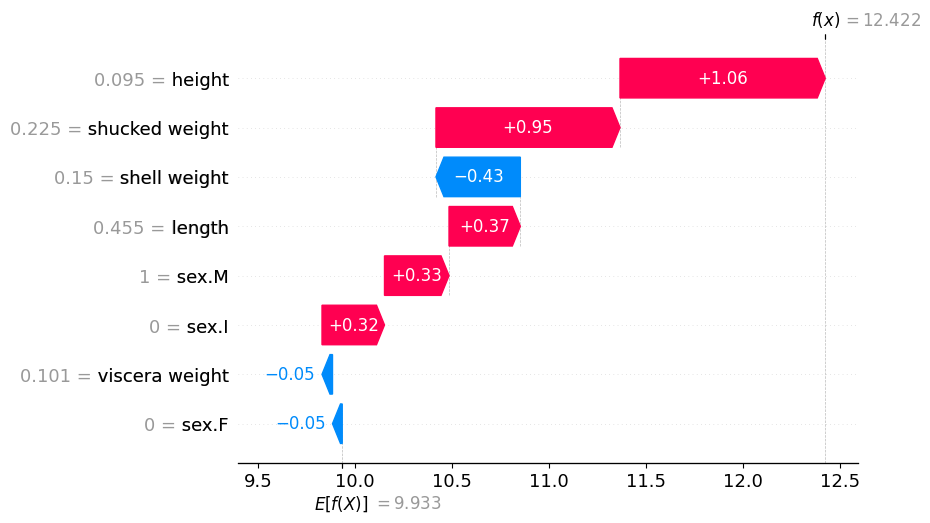

In [35]:
shap.plots.waterfall(shap_values[0])

## Force plot

In [66]:
shap.plots.force(shap_values[0:100])

## Absolute Mean SHAP

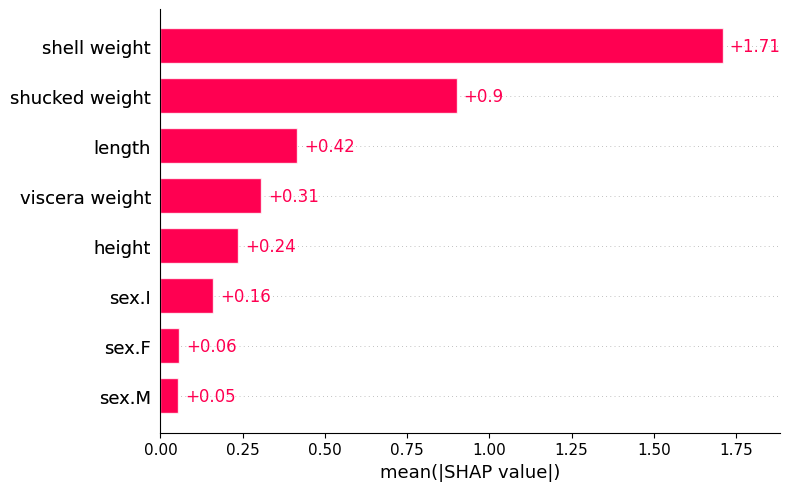

In [68]:
shap.plots.bar(shap_values)

## Beeswarm plot

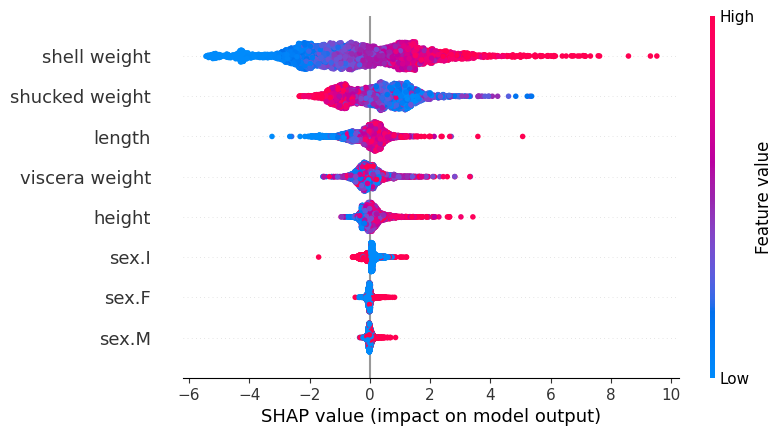

In [70]:
shap.plots.beeswarm(shap_values)

In [71]:
shap_values[:, "shell weight"]

.values =
array([-0.43476838, -2.2873337 , -0.9619946 , ...,  0.6896788 ,
        0.6055843 ,  1.4847205 ], shape=(4177,), dtype=float32)

.base_values =
array([9.93266, 9.93266, 9.93266, ..., 9.93266, 9.93266, 9.93266],
      shape=(4177,), dtype=float32)

.data =
array([0.15 , 0.07 , 0.21 , ..., 0.308, 0.296, 0.495], shape=(4177,))

## Dependence plots

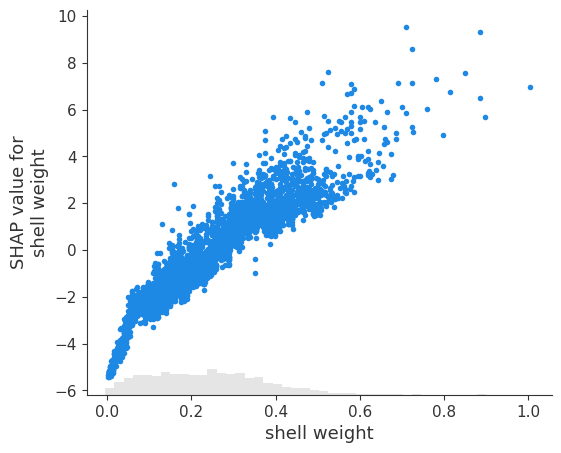

In [72]:
#Plot 1: shell weight
shap.plots.scatter(shap_values[:, "shell weight"])

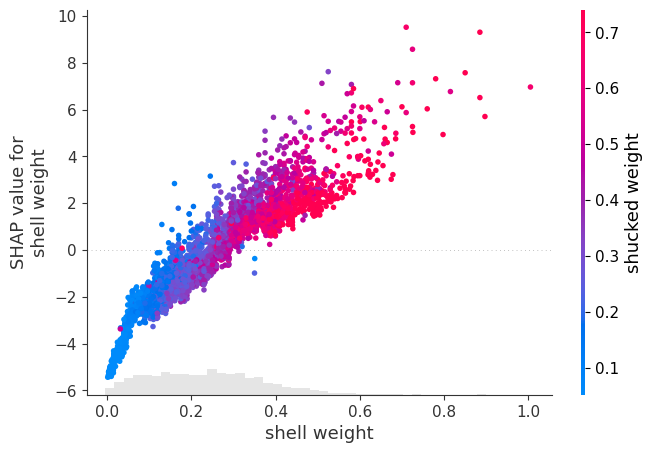

In [74]:
shap.plots.scatter(shap_values[:, "shell weight"], color=shap_values[:, "shucked weight"])

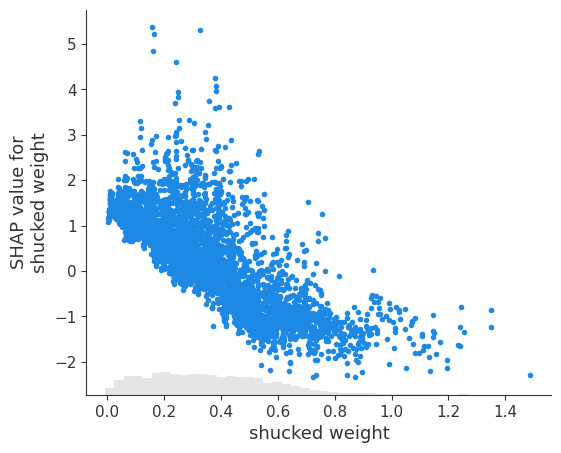

In [75]:
shap.plots.scatter(shap_values[:, "shucked weight"])